# 🤟 Eksplorasi Dataset & Analisis Model Handsign SVM

Notebook ini digunakan untuk:
1. Eksplorasi dataset gambar ArSL
2. Visualisasi distribusi kelas
3. Analisis hasil ekstraksi fitur MediaPipe
4. Perbandingan performa model SVM sebelum vs sesudah tuning
5. Visualisasi Confusion Matrix & per-class accuracy

In [25]:
import os
import sys
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from pathlib import Path

ROOT = Path(os.getcwd()).parent if os.getcwd().endswith('notebooks') else Path(os.getcwd())
DATA_DIR = ROOT.parent / 'data' / 'Arabic Sign Language ArSL dataset'

print(f'ROOT  : {ROOT}')
print(f'DATA  : {DATA_DIR}')
print(f'DATA exists: {DATA_DIR.exists()}')

ROOT  : c:\Users\Arif\Github\lomba\qurava-unej\AI\modelling
DATA  : c:\Users\Arif\Github\lomba\qurava-unej\AI\data\Arabic Sign Language ArSL dataset
DATA exists: True


## 1. Eksplorasi Struktur Dataset

In [26]:
# Mapping class index (YOLO) ke nama label string yang dipakai di web
CLASS_MAP = {
    0: 'aleff',  # ALIF
    1: 'bb',     # BAA
    2: 'ta',     # TA
    3: 'thaa',   # THA
    4: 'jeem',   # JEEM
    5: 'haa',    # HAA
    6: 'khaa',   # KHAA
    7: 'dal',    # DELL
    8: 'thal',   # DHELL
    9: 'ra',     # RAA
    10: 'zay',   # ZAY
    11: 'seen',  # SEEN
    12: 'sheen', # SHEEN
    13: 'saad',  # SAD
    14: 'dhad',  # DAD
    15: 'taa',   # TAA
    16: 'dha',   # DHAA
    17: 'ain',   # AYN
    18: 'ghain', # GHAYN
    19: 'fa',    # FAA
    20: 'gaaf',  # QAAF
    21: 'kaaf',  # KAAF
    22: 'laam',  # LAAM
    23: 'meem',  # MEEM
    24: 'nun',   # NOON
    25: 'ha',    # HA
    26: 'waw',   # WAW
    27: 'ya',    # YA
}

splits = ['train', 'valid', 'test']
counts = {split: {v: 0 for v in CLASS_MAP.values()} for split in splits}

for split in splits:
    label_dir = DATA_DIR / split / 'labels'
    if not label_dir.exists():
        print(f'⚠️  {split}/labels tidak ditemukan')
        continue
    for label_file in label_dir.glob('*.txt'):
        with open(label_file) as f:
            for line in f:
                parts = line.strip().split()
                if parts:
                    cls_idx = int(parts[0])
                    cls_name = CLASS_MAP.get(cls_idx, f'unknown_{cls_idx}')
                    if cls_name in counts[split]:
                        counts[split][cls_name] += 1

df_counts = pd.DataFrame(counts).fillna(0).astype(int)
df_counts['total'] = df_counts.sum(axis=1)
df_counts = df_counts.sort_values('total', ascending=False)
print(df_counts.to_string())

       train  valid  test  total
aleff    969     59    21   1049
saad     564     35    12    611
dhad     548     35    12    595
sheen    543     34    11    588
seen     522     33    11    566
taa      519     33    11    563
ra       516     32    11    559
thal     504     32    11    547
kaaf     504     31    11    546
ghain    495     31    10    536
waw      495     31    10    536
zay      493     31    10    534
gaaf     492     31    10    533
dha      492     31    10    533
fa       492     31    10    533
meem     489     31    10    530
laam     489     31    10    530
ha       489     30    10    529
ya       489     30    10    529
ain      489     30    10    529
dal      483     30    10    523
thaa     483     30    10    523
jeem     480     30    10    520
khaa     480     30    10    520
haa      480     30    10    520
ta       477     30    10    517
bb       465     28    10    503
nun        0      0     0      0


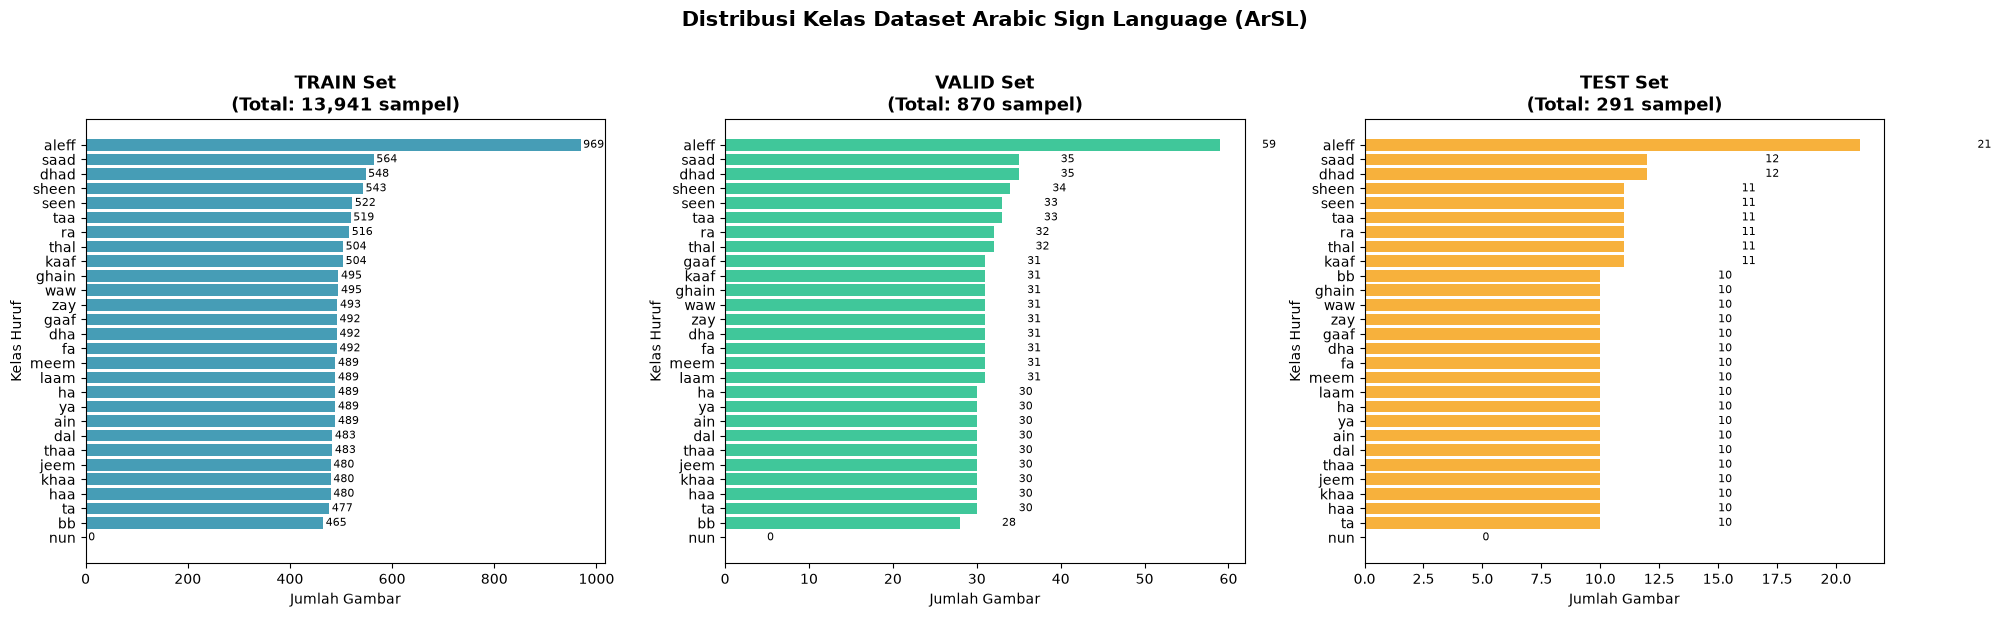

✅ Tersimpan di output/class_distribution.png


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

colors = ['#1885A4', '#10B981', '#F59E0B']

for ax, split, color in zip(axes, splits, colors):
    data = df_counts[split].sort_values(ascending=True)
    bars = ax.barh(data.index, data.values, color=color, alpha=0.8)
    ax.set_title(f'{split.upper()} Set\n(Total: {data.sum():,} sampel)', fontsize=13, fontweight='bold')
    ax.set_xlabel('Jumlah Gambar')
    ax.set_ylabel('Kelas Huruf')
    
    for bar, val in zip(bars, data.values):
        ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
                f'{val}', va='center', fontsize=8)

plt.suptitle('Distribusi Kelas Dataset Arabic Sign Language (ArSL)', 
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(ROOT / 'output' / 'class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Tersimpan di output/class_distribution.png')

## 2. Lihat Contoh Gambar Dataset

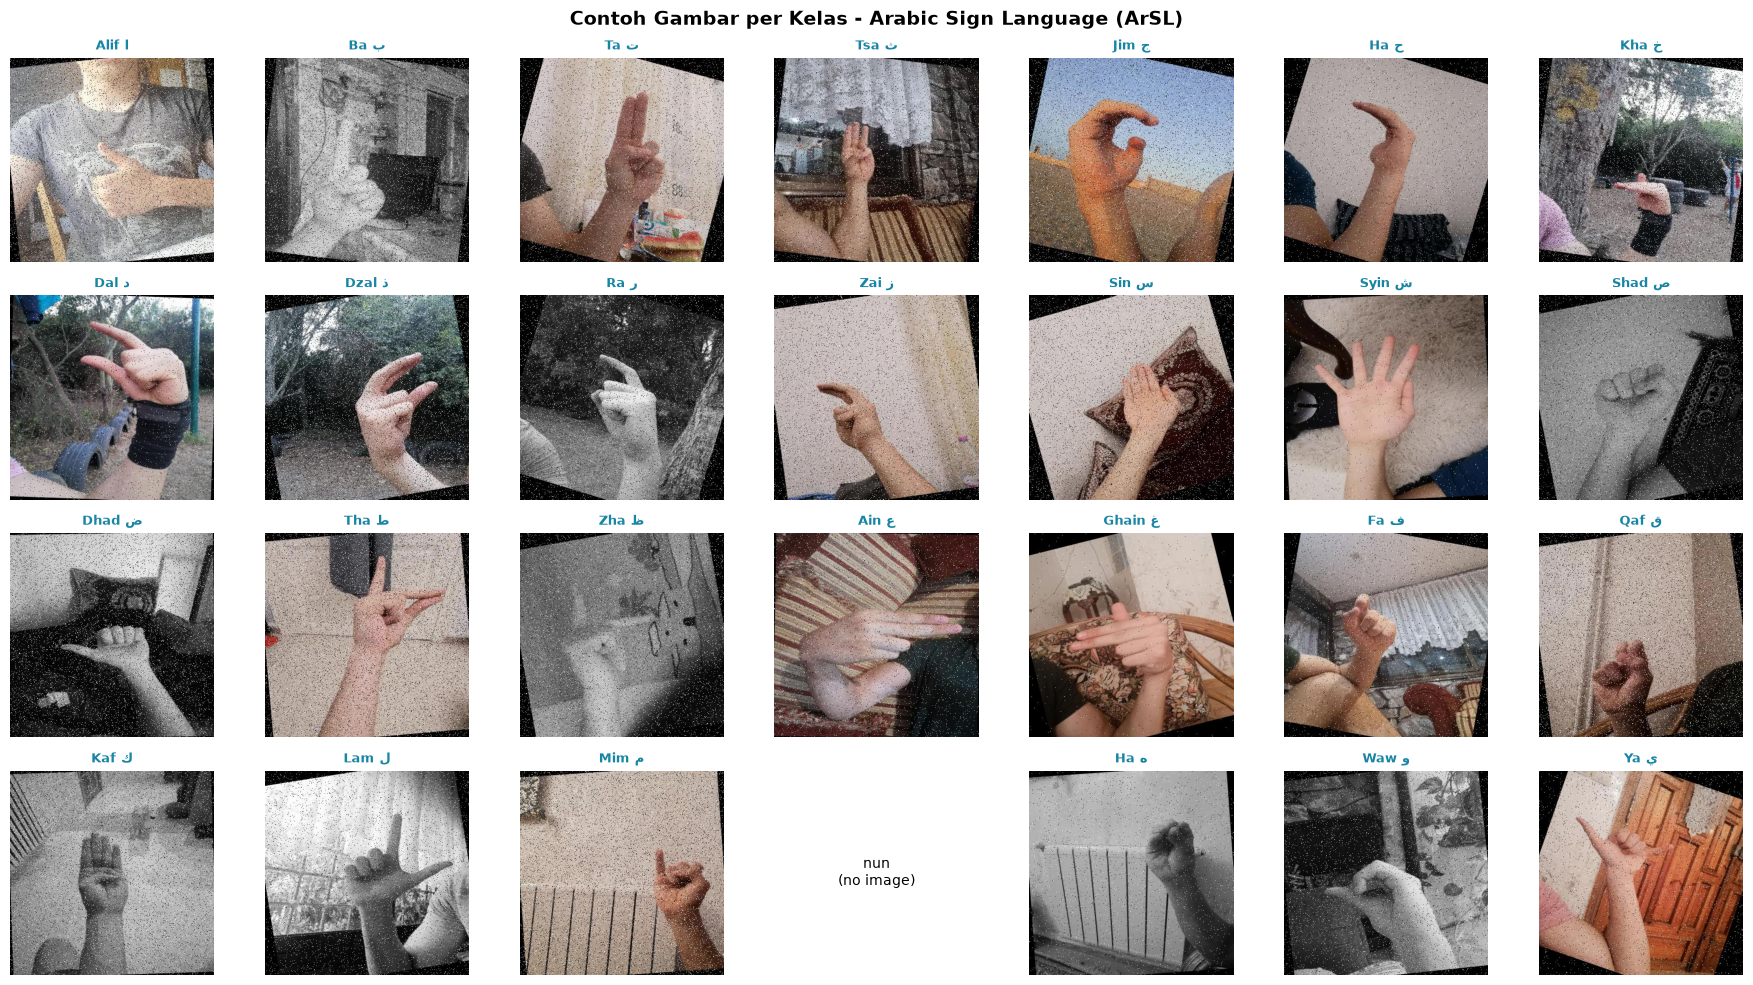

✅ Tersimpan di output/sample_images.png


In [28]:
import random
import cv2

def get_sample_per_class(split='train', n_classes=28):
    """Ambil 1 sampel gambar per kelas."""
    image_dir = DATA_DIR / split / 'images'
    label_dir = DATA_DIR / split / 'labels'
    
    samples = {v: None for v in CLASS_MAP.values()}
    
    for label_file in label_dir.glob('*.txt'):
        with open(label_file) as f:
            first_line = f.readline().strip().split()
            if not first_line:
                continue
            cls_idx = int(first_line[0])
            cls_name = CLASS_MAP.get(cls_idx)
            if cls_name and samples[cls_name] is None:
                img_path = image_dir / (label_file.stem + '.jpg')
                if img_path.exists():
                    samples[cls_name] = str(img_path)
    
    return samples

samples = get_sample_per_class()

fig, axes = plt.subplots(4, 7, figsize=(18, 10))
axes_flat = axes.flatten()

hijaiyah_names = {
    'aleff': 'Alif ا', 'bb': 'Ba ب', 'ta': 'Ta ت', 'thaa': 'Tsa ث',
    'jeem': 'Jim ج', 'haa': 'Ha ح', 'khaa': 'Kha خ', 'dal': 'Dal د',
    'thal': 'Dzal ذ', 'ra': 'Ra ر', 'zay': 'Zai ز', 'seen': 'Sin س',
    'sheen': 'Syin ش', 'saad': 'Shad ص', 'dhad': 'Dhad ض', 'taa': 'Tha ط',
    'dha': 'Zha ظ', 'ain': 'Ain ع', 'ghain': 'Ghain غ', 'fa': 'Fa ف',
    'gaaf': 'Qaf ق', 'kaaf': 'Kaf ك', 'laam': 'Lam ل', 'meem': 'Mim م',
    'nun': 'Nun ن', 'ha': 'Ha ه', 'waw': 'Waw و', 'ya': 'Ya ي'
}

for i, (cls, path) in enumerate(samples.items()):
    ax = axes_flat[i]
    if path:
        img = cv2.imread(path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.set_title(hijaiyah_names.get(cls, cls), fontsize=9, fontweight='bold', color='#1885A4')
    else:
        ax.text(0.5, 0.5, f'{cls}\n(no image)', ha='center', va='center', transform=ax.transAxes)
    ax.axis('off')

for j in range(len(samples), len(axes_flat)):
    axes_flat[j].axis('off')

plt.suptitle('Contoh Gambar per Kelas - Arabic Sign Language (ArSL)', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(ROOT / 'output' / 'sample_images.png', dpi=120, bbox_inches='tight')
plt.show()
print('✅ Tersimpan di output/sample_images.png')

## 3. Analisis Fitur yang Sudah Diekstraksi

In [29]:
train_csv = ROOT / 'data' / 'features_train.csv'
valid_csv = ROOT / 'data' / 'features_valid.csv'
test_csv  = ROOT / 'data' / 'features_test.csv'

if not train_csv.exists():
    print('⚠️  features_train.csv belum ada. Jalankan dulu: python 1_extract_features.py')
else:
    df_train = pd.read_csv(train_csv)
    df_valid = pd.read_csv(valid_csv)
    df_test  = pd.read_csv(test_csv)
    
    print(f'Train: {len(df_train):,} baris | {df_train["label"].nunique()} kelas')
    print(f'Valid: {len(df_valid):,} baris | {df_valid["label"].nunique()} kelas')
    print(f'Test : {len(df_test):,} baris  | {df_test["label"].nunique()} kelas')
    print(f'\nShape train: {df_train.shape}')
    print(f'\nKolom: {list(df_train.columns[:10])} ... (78 fitur + label + split)')
    df_train.head()

Train: 963 baris | 27 kelas
Valid: 764 baris | 27 kelas
Test : 248 baris  | 27 kelas

Shape train: (963, 80)

Kolom: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9'] ... (78 fitur + label + split)


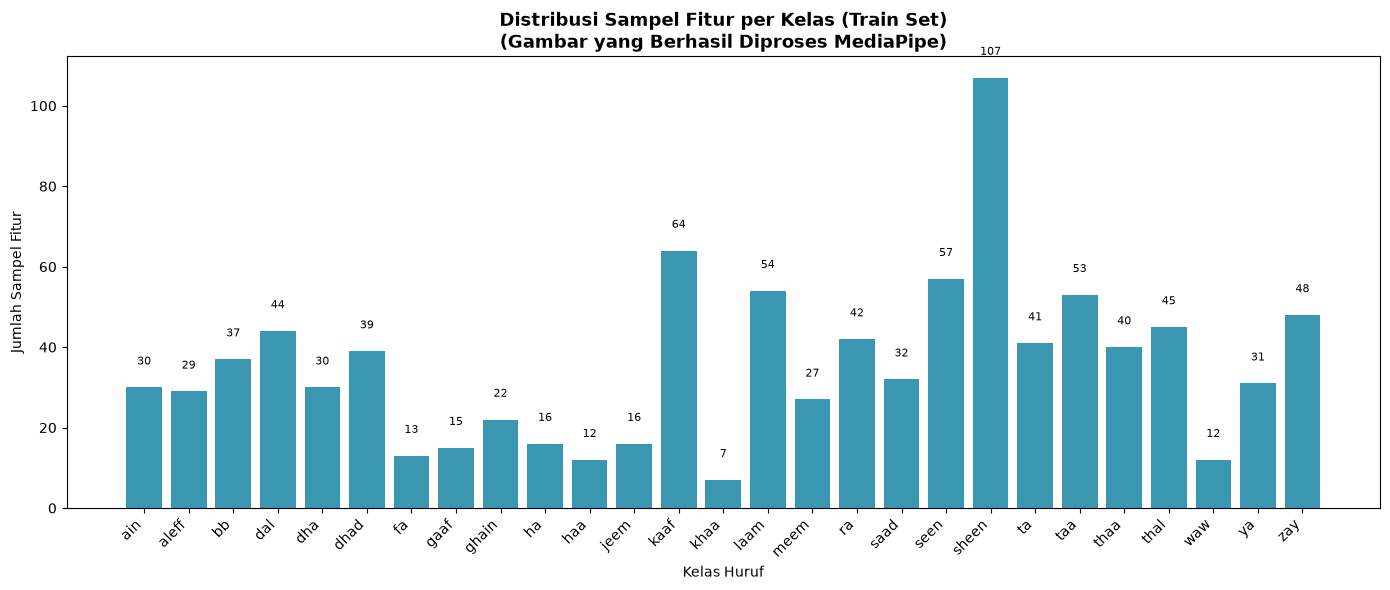

In [30]:
if 'df_train' in locals():
    fig, ax = plt.subplots(figsize=(14, 6))
    
    class_counts = df_train['label'].value_counts().sort_index()
    bars = ax.bar(class_counts.index, class_counts.values, color='#1885A4', alpha=0.85)
    
    ax.set_title('Distribusi Sampel Fitur per Kelas (Train Set)\n(Gambar yang Berhasil Diproses MediaPipe)', 
                 fontsize=13, fontweight='bold')
    ax.set_xlabel('Kelas Huruf')
    ax.set_ylabel('Jumlah Sampel Fitur')
    plt.xticks(rotation=45, ha='right')
    
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                str(int(bar.get_height())), ha='center', va='bottom', fontsize=8)
    
    plt.tight_layout()
    plt.savefig(ROOT / 'output' / 'feature_distribution.png', dpi=150)
    plt.show()

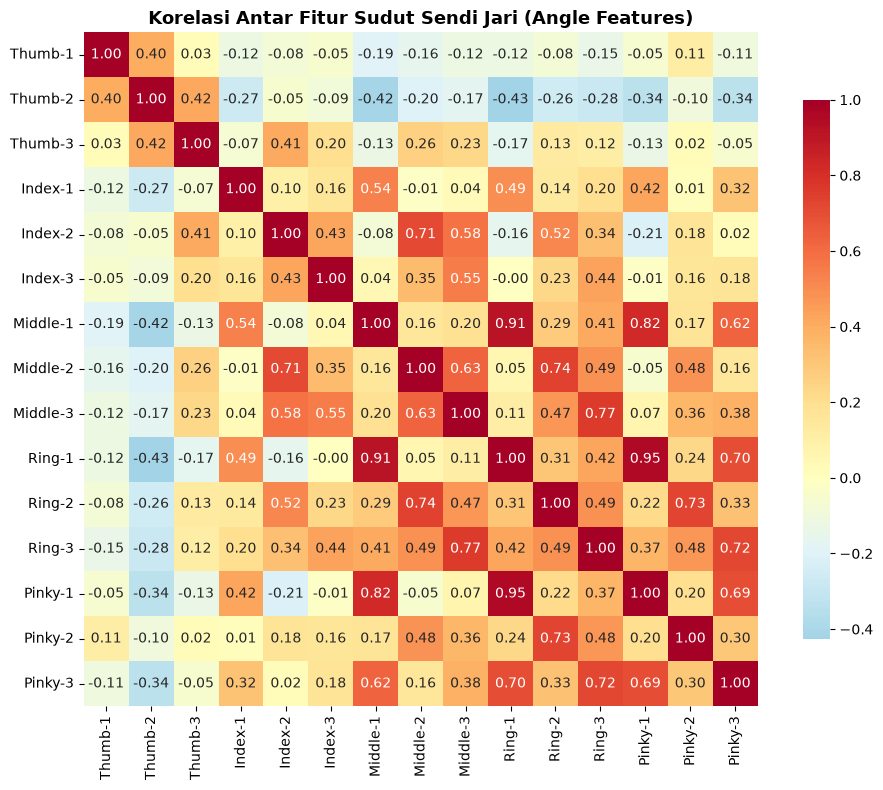

✅ Tersimpan di output/angle_correlation.png


In [31]:
if 'df_train' in locals():
    angle_cols = [f'f{i}' for i in range(63, 78)]
    angle_names = [
        'Thumb-1', 'Thumb-2', 'Thumb-3',
        'Index-1', 'Index-2', 'Index-3',
        'Middle-1', 'Middle-2', 'Middle-3',
        'Ring-1', 'Ring-2', 'Ring-3',
        'Pinky-1', 'Pinky-2', 'Pinky-3',
    ]
    
    corr = df_train[angle_cols].rename(columns=dict(zip(angle_cols, angle_names))).corr()
    
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlBu_r', center=0,
                square=True, ax=ax, cbar_kws={'shrink': 0.8})
    ax.set_title('Korelasi Antar Fitur Sudut Sendi Jari (Angle Features)', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(ROOT / 'output' / 'angle_correlation.png', dpi=150)
    plt.show()
    print('✅ Tersimpan di output/angle_correlation.png')

## 4. Analisis Hasil Tuning

In [32]:
results_file = ROOT / 'output' / 'training_results.json'

if not results_file.exists():
    print('⚠️  training_results.json belum ada. Jalankan dulu: python 2_train_tuning.py')
else:
    with open(results_file) as f:
        results = json.load(f)
    
    print('=== HASIL TUNING MODEL SVM ===')
    print(f'Best Parameters : {results["best_params"]}')
    print(f'CV Score (Train) : {results["cv_score"]:.4f}')
    print(f'Accuracy (Test)  : {results["accuracy"]:.4f}')
    print(f'F1 Macro (Test)  : {results["f1_macro"]:.4f}')
    print()
    
    # Per-class accuracy
    if 'per_class' in results:
        df_cls = pd.DataFrame(results['per_class']).T
        print('Per-Class Performance:')
        print(df_cls.to_string())

=== HASIL TUNING MODEL SVM ===
Best Parameters : {'C': 10, 'class_weight': None, 'gamma': 'scale', 'kernel': 'linear'}
CV Score (Train) : 0.9172
Accuracy (Test)  : 0.9556
F1 Macro (Test)  : 0.9527



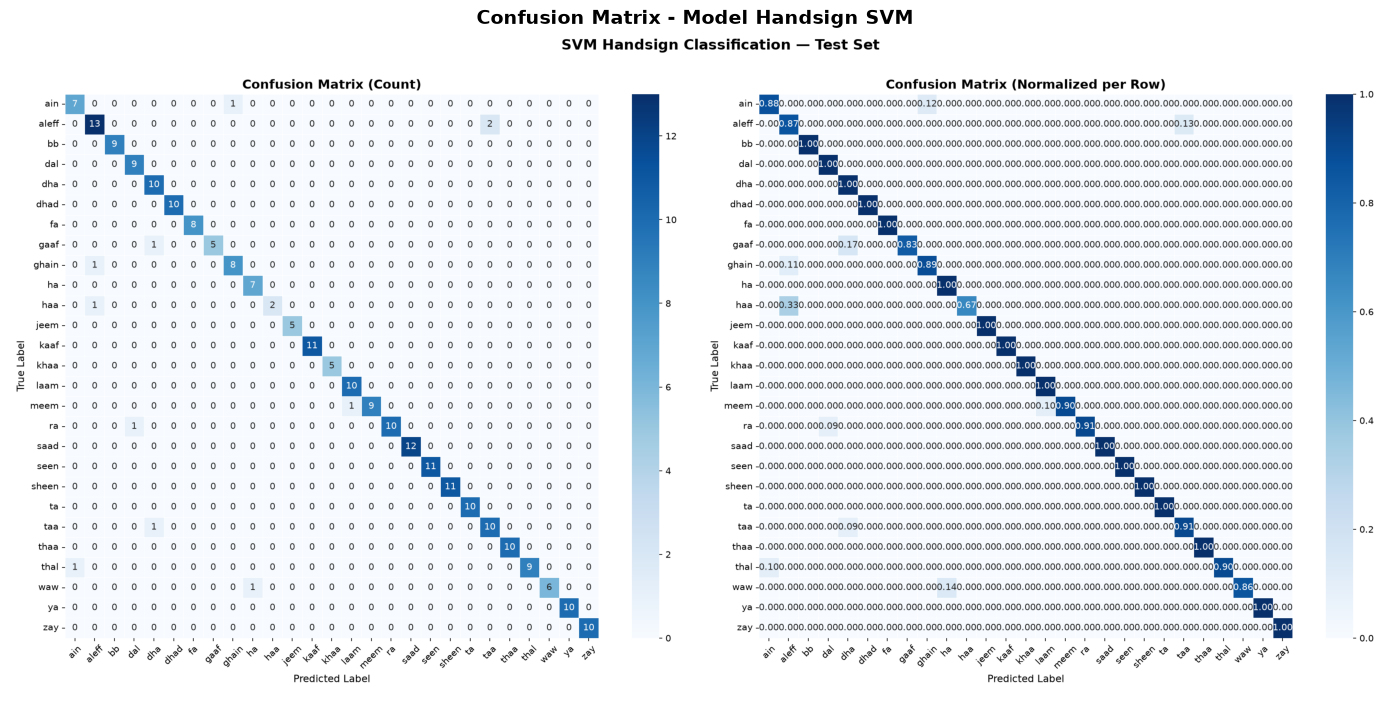

In [33]:
cm_file = ROOT / 'output' / 'confusion_matrix.png'

if cm_file.exists():
    img = mpimg.imread(str(cm_file))
    fig, ax = plt.subplots(figsize=(14, 12))
    ax.imshow(img)
    ax.axis('off')
    ax.set_title('Confusion Matrix - Model Handsign SVM', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('⚠️  confusion_matrix.png belum ada. Jalankan dulu: python 2_train_tuning.py')

## 5. Analisis Per-Class Accuracy

In [ ]:
if 'results' in locals() and 'per_class' in results:
    df_cls = pd.DataFrame(results['per_class']).T
    df_cls['f1-score'] = pd.to_numeric(df_cls['f1-score'])
    df_cls = df_cls.sort_values('f1-score', ascending=True)
    
    fig, ax = plt.subplots(figsize=(10, 10))
    colors = ['#ef4444' if v < 0.6 else '#f59e0b' if v < 0.85 else '#10B981' 
              for v in df_cls['f1-score']]
    bars = ax.barh(df_cls.index, df_cls['f1-score'], color=colors, alpha=0.85)
    
    ax.set_title('F1-Score per Kelas Huruf Hijaiyah\n(Merah < 0.6 | Kuning < 0.85 | Hijau ≥ 0.85)', 
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('F1-Score')
    ax.axvline(0.85, color='green', linestyle='--', alpha=0.5, label='Target 85%')
    ax.axvline(0.6, color='red', linestyle='--', alpha=0.5, label='Batas Minimum 60%')
    ax.set_xlim(0, 1.1)
    ax.legend()
    
    for bar, val in zip(bars, df_cls['f1-score']):
        ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                f'{val:.3f}', va='center', fontsize=9)
    
    plt.tight_layout()
    plt.savefig(ROOT / 'output' / 'per_class_f1.png', dpi=150)
    plt.show()
    print('✅ Tersimpan di output/per_class_f1.png')

: 

## 6. Validasi Model ONNX

In [ ]:
import onnxruntime as rt

onnx_path = ROOT / 'output' / 'handsign_svm.onnx'
label_map_path = ROOT / 'output' / 'label_map.json'

if not onnx_path.exists():
    print('⚠️  handsign_svm.onnx belum ada. Jalankan dulu: python 3_export_onnx.py')
else:
    sess = rt.InferenceSession(str(onnx_path))
    with open(label_map_path) as f:
        label_map = json.load(f)
    
    print(f'✅ Model ONNX loaded berhasil!')
    print(f'Input:  {sess.get_inputs()[0].name} shape={sess.get_inputs()[0].shape} type={sess.get_inputs()[0].type}')
    print(f'Output: {[o.name for o in sess.get_outputs()]}')
    print(f'Label map ({len(label_map)} kelas): {label_map}')
    
    dummy = np.random.rand(5, 78).astype(np.float32)
    outputs = sess.run(None, {'float_input': dummy})
    
    pred_labels = [label_map[int(p)] for p in outputs[0]]
    pred_probs  = [float(max(row)) for row in outputs[1]]
    
    print('\n=== Test Inferensi (5 sampel dummy) ===')
    for i, (lbl, prob) in enumerate(zip(pred_labels, pred_probs)):
        print(f'  Sampel {i+1}: {lbl} ({prob:.1%} confidence)')
    
    print('\n✅ Model ONNX siap digunakan di web Qurava!')

In [ ]:
import os

old_model = Path('../../public/models/handsign_svm.onnx')
new_model = ROOT / 'output' / 'handsign_svm.onnx'

if old_model.exists() and new_model.exists():
    old_size = old_model.stat().st_size / 1024 / 1024
    new_size = new_model.stat().st_size / 1024 / 1024
    
    print(f'Model Lama: {old_size:.2f} MB ({old_model})')
    print(f'Model Baru: {new_size:.2f} MB ({new_model})')
    print(f'Selisih   : {abs(new_size - old_size):.2f} MB ({"lebih besar" if new_size > old_size else "lebih kecil"})')